In [73]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [74]:
def euler_method(f, t_span, y0, h, exact_solution=None):
  t0, tf = t_span
  t_values = np.arange(t0, tf+h, h)
  y_values = [y0]
  # Store iteration results for the table
  table_data = {'Iteration': [0], 't': [t0], 'y': [y0]}
  # Euler's Method Iteration
  y = y0
  for i, t in enumerate(t_values[:-1]):
    y += h * f(t, y)    # y_N+1 = y_N + hf(t, y)
    y_values.append(y)
    table_data['Iteration'].append(i+1)
    table_data['t'].append(t+h)
    table_data['y'].append(y)
  # Display the solution table
  df = pd.DataFrame(table_data)
  print("Solution Table")
  print(df.to_string(index=False))
  # Plot the numerical solution
  plt.figure(figsize=(10, 5))
  plt.plot(t_values, y_values, label='Euler Solution', marker='o')
  if exact_solution:
    exact_y = [exact_solution(t) for t in t_values]
    plt.plot(t_values, exact_y, label='Exact Solution', linestyle='--')
  plt.xlabel('t')
  plt.ylabel('y')
  plt.title("Euler Method Solution of ODE")
  plt.legend()
  plt.grid(True)
  plt.show()
  # Plot the error if exact solution is provided
  if exact_solution:
    error = np.abs(np.array(y_values) - np.array(exact_y))
    plt.figure(figsize=(10, 5))
    plt.plot(t_values, error, label='Error', color='red')
    plt.xlabel('t')
    plt.ylabel('Error')
    plt.title("Error Plot (Euler Method)")
    plt.legend()
    plt.grid(True)
    plt.show()

In [75]:
# Example Usage
def example_function(t, y):
  # return 1 + t * y**2
  # return t - y
  return y - t
  # return -2 * y + np.sin(t)

In [76]:
def exact_solution(t):
  # return t - 1 + 2 * np.exp(-t)
  return t + 1 + (1/2) * np.exp(t)
  # return (np.sin(t) - np.cos(t)) / 5 + (np.cos(t) + 2 * np.sin(t)) * np.exp(-2 * t) / 5

In [77]:
t0, tf = 0, 2
y0 = 1.5
step_size = 0.1

Solution Table
 Iteration   t        y
         0 0.0 1.500000
         1 0.1 1.650000
         2 0.2 1.805000
         3 0.3 1.965500
         4 0.4 2.132050
         5 0.5 2.305255
         6 0.6 2.485780
         7 0.7 2.674359
         8 0.8 2.871794
         9 0.9 3.078974
        10 1.0 3.296871
        11 1.1 3.526558
        12 1.2 3.769214
        13 1.3 4.026136
        14 1.4 4.298749
        15 1.5 4.588624
        16 1.6 4.897486
        17 1.7 5.227235
        18 1.8 5.579959
        19 1.9 5.957955
        20 2.0 6.363750


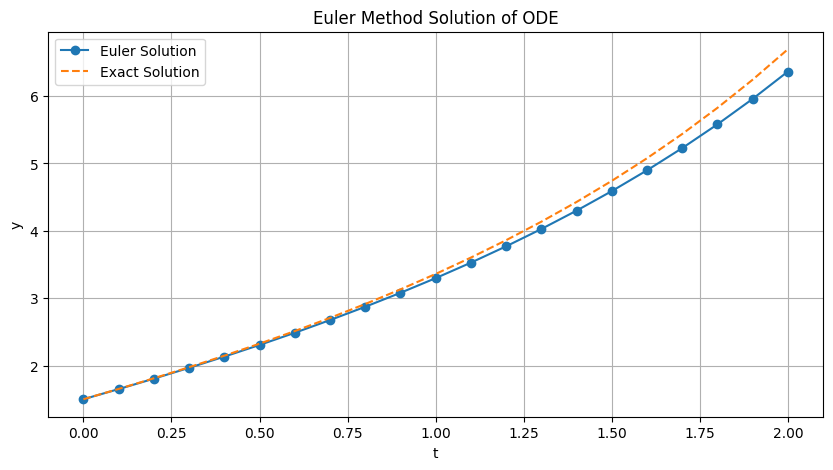

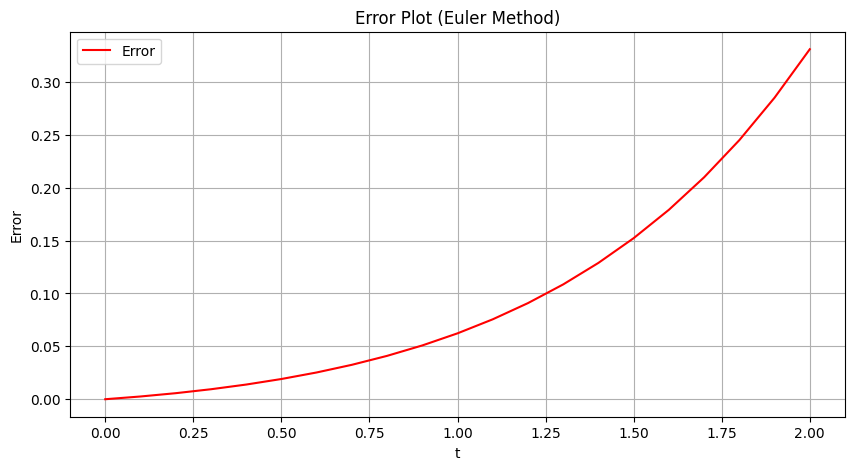

In [78]:
# euler_method(example_function, (t0, tf), y0, step_size, exact_solution=None)    # if exact sol. is NOT known
euler_method(example_function, (t0, tf), y0, step_size, exact_solution=exact_solution)    # if exact sol. is known